In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [2]:
# =========================
# 1. Parameter settings
# =========================

file_path = "data/event-saccades.csv"
selected_tois = ["ET_Item_008", "ET_Item_026", "ET_Item_061", "ET_Item_113"]

n_bins = 24
bin_width = 360 / n_bins  # Each directional bin spans 15°

# =========================
# 2. Load data
# =========================
df = pd.read_csv(file_path)
df

,ParticipantID,Media,Event_type,Validity,EventIndex,Start,Stop,Duration,Saccade_direction,Average_velocity,Peak_velocity,Saccade_amplitude,Start_position_X,Start_position_Y,Landing_position_X,Landing_position_Y,StartX,StartY,LandX,LandY
0,P001,ET_Item_001,Saccade,Whole,1,181,217,36,43.19,121.81,187.58,4.28,0.34887,0.42212,0.46605,0.31211,669.8304,455.8896,894.8160,337.0788
1,P001,ET_Item_001,Saccade,Whole,2,429,477,48,211.19,128.91,209.44,6.15,0.46605,0.31211,0.28534,0.42153,894.8160,337.0788,547.8528,455.2524
2,P001,ET_Item_001,Saccade,Whole,3,705,745,40,318.33,136.03,218.10,5.30,0.28534,0.42153,0.43120,0.55136,547.8528,455.2524,827.9040,595.4688
3,P001,ET_Item_001,Saccade,Whole,4,933,957,24,308.03,55.46,70.07,1.27,0.43120,0.55136,0.46284,0.59182,827.9040,595.4688,888.6528,639.1656
4,P001,ET_Item_001,Saccade,Whole,5,1097,1137,40,8.05,106.80,168.16,4.31,0.46284,0.59182,0.59626,0.57296,888.6528,639.1656,1144.8192,618.7968
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1977947,P175,ET_Item_116,Saccade,Whole,40,10113,10133,20,195.20,74.72,89.86,1.24,0.30049,0.90407,0.25751,0.91575,576.9408,976.3956,494.4192,989.0100
1977948,P175,ET_Item_116,Saccade,Whole,41,10349,10365,16,5.46,50.89,56.70,0.94,0.25751,0.91575,0.28717,0.91292,494.4192,989.0100,551.3664,985.9536
1977949,P175,ET_Item_116,Saccade,Whole,42,10773,10797,24,340.66,115.30,156.80,2.58,0.28717,0.91292,0.37548,0.94391,551.3664,985.9536,720.9216,1019.4228
1977950,P175,ET_Item_116,Saccade,Whole,43,10929,10945,16,144.93,42.20,57.32,1.26,0.37548,0.94391,0.35361,0.92855,720.9216,1019.4228,678.9312,1002.8340


In [3]:
df["Media"] = (
    df["Media"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(2)
)

# Keep only the specified media
df = df[df["Media"].isin(selected_tois)].copy()

# Keep only valid, complete saccade events
df = df[
    df["Event_type"].astype(str).str.strip().str.lower().eq("saccade")
].copy()

df = df[
    df["Validity"].astype(str).str.strip().str.lower().eq("whole")
].copy()

# Convert direction values to numeric
df["Saccade_direction"] = pd.to_numeric(
    df["Saccade_direction"],
    errors="coerce"
)

df = df.dropna(
    subset=["ParticipantID", "Media", "Saccade_direction"]
).copy()

# Normalize angles to [0, 360)
df["direction_deg"] = df["Saccade_direction"] % 360


In [4]:
df

,ParticipantID,Media,Event_type,Validity,EventIndex,Start,Stop,Duration,Saccade_direction,Average_velocity,...,Saccade_amplitude,Start_position_X,Start_position_Y,Landing_position_X,Landing_position_Y,StartX,StartY,LandX,LandY,direction_deg
854,P001,ET_Item_008,Saccade,Whole,1,191,247,56,110.47,226.86,...,12.11,0.55165,0.80726,0.34974,0.26635,1059.1680,871.8408,671.5008,287.6580,110.47
855,P001,ET_Item_008,Saccade,Whole,2,395,423,28,110.96,97.27,...,2.35,0.34974,0.26635,0.30496,0.14945,671.5008,287.6580,585.5232,161.4060,110.96
856,P001,ET_Item_008,Saccade,Whole,3,587,619,32,337.35,79.80,...,2.94,0.30496,0.14945,0.38353,0.18224,585.5232,161.4060,736.3776,196.8192,337.35
857,P001,ET_Item_008,Saccade,Whole,4,787,823,36,9.28,123.92,...,4.67,0.38353,0.18224,0.51867,0.16017,736.3776,196.8192,995.8464,172.9836,9.28
858,P001,ET_Item_008,Saccade,Whole,5,1107,1143,36,3.76,79.40,...,2.66,0.51867,0.16017,0.59898,0.15488,995.8464,172.9836,1150.0416,167.2704,3.76
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1977787,P175,ET_Item_113,Saccade,Whole,79,23631,23651,20,97.26,55.11,...,0.88,0.56162,0.69167,0.55499,0.63963,1078.3104,747.0036,1065.5808,690.8004,97.26
1977788,P175,ET_Item_113,Saccade,Whole,80,23867,23907,40,60.59,135.08,...,6.06,0.55499,0.63963,0.69287,0.39506,1065.5808,690.8004,1330.3104,426.6648,60.59
1977789,P175,ET_Item_113,Saccade,Whole,81,24191,24207,16,72.54,52.25,...,0.68,0.69287,0.39506,0.70388,0.36008,1330.3104,426.6648,1351.4496,388.8864,72.54
1977793,P175,ET_Item_113,Saccade,Whole,85,24719,24783,64,289.63,119.67,...,6.32,0.45014,0.41735,0.56281,0.73316,864.2688,450.7380,1080.5952,791.8128,289.63


In [5]:
# =========================
# 3. Divide directions into 24 bins
# =========================

# The 24 directional bins are centered at 0°, 15°, 30°, ..., 345°
df["direction_bin"] = np.floor(
    ((df["direction_deg"] + bin_width / 2) % 360)
    / bin_width
).astype(int)

df["direction_bin_deg"] = (
    df["direction_bin"] * bin_width
)
df

,ParticipantID,Media,Event_type,Validity,EventIndex,Start,Stop,Duration,Saccade_direction,Average_velocity,...,Start_position_Y,Landing_position_X,Landing_position_Y,StartX,StartY,LandX,LandY,direction_deg,direction_bin,direction_bin_deg
854,P001,ET_Item_008,Saccade,Whole,1,191,247,56,110.47,226.86,...,0.80726,0.34974,0.26635,1059.1680,871.8408,671.5008,287.6580,110.47,7,105.0
855,P001,ET_Item_008,Saccade,Whole,2,395,423,28,110.96,97.27,...,0.26635,0.30496,0.14945,671.5008,287.6580,585.5232,161.4060,110.96,7,105.0
856,P001,ET_Item_008,Saccade,Whole,3,587,619,32,337.35,79.80,...,0.14945,0.38353,0.18224,585.5232,161.4060,736.3776,196.8192,337.35,22,330.0
857,P001,ET_Item_008,Saccade,Whole,4,787,823,36,9.28,123.92,...,0.18224,0.51867,0.16017,736.3776,196.8192,995.8464,172.9836,9.28,1,15.0
858,P001,ET_Item_008,Saccade,Whole,5,1107,1143,36,3.76,79.40,...,0.16017,0.59898,0.15488,995.8464,172.9836,1150.0416,167.2704,3.76,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1977787,P175,ET_Item_113,Saccade,Whole,79,23631,23651,20,97.26,55.11,...,0.69167,0.55499,0.63963,1078.3104,747.0036,1065.5808,690.8004,97.26,6,90.0
1977788,P175,ET_Item_113,Saccade,Whole,80,23867,23907,40,60.59,135.08,...,0.63963,0.69287,0.39506,1065.5808,690.8004,1330.3104,426.6648,60.59,4,60.0
1977789,P175,ET_Item_113,Saccade,Whole,81,24191,24207,16,72.54,52.25,...,0.39506,0.70388,0.36008,1330.3104,426.6648,1351.4496,388.8864,72.54,5,75.0
1977793,P175,ET_Item_113,Saccade,Whole,85,24719,24783,64,289.63,119.67,...,0.41735,0.56281,0.73316,864.2688,450.7380,1080.5952,791.8128,289.63,19,285.0


In [6]:
# =========================
# 4. Calculate directional proportions for each participant
# =========================

# Saccade count for each participant, item, and direction
counts = (
    df.groupby(
        ["Media", "ParticipantID", "direction_bin"]
    )
    .size()
    .unstack(fill_value=0)
)

# Ensure all 24 directions are represented
counts = counts.reindex(
    columns=range(n_bins),
    fill_value=0
)

# Normalize within each participant
# Prevent participants with more saccades from dominating group results
participant_proportions = counts.div(
    counts.sum(axis=1),
    axis=0
)


# =========================
# 5. Calculate mean directional proportions across participants
# =========================

group_mean = (
    participant_proportions
    .groupby(level="Media")
    .mean()
)
#Standard error of the mean: reflects uncertainty in the estimated group mean directional proportion
#Error bars in the rose plots represent uncertainty in directional proportions across participants, not variation in saccade counts
group_sem = (
    participant_proportions
    .groupby(level="Media")
    .sem()
)

# Arrange in the specified order
available_tois = [
    toi for toi in selected_tois
    if toi in group_mean.index
]

group_mean = group_mean.loc[available_tois]
group_sem = group_sem.loc[available_tois]
print(group_sem.round(4))

direction_bin      0       1       2       3       4       5       6       7   \
Media                                                                           
ET_Item_008    0.0033  0.0022  0.0015  0.0013  0.0012  0.0014  0.0023  0.0018   
ET_Item_026    0.0035  0.0022  0.0018  0.0017  0.0015  0.0017  0.0020  0.0019   
ET_Item_061    0.0023  0.0023  0.0018  0.0020  0.0019  0.0022  0.0033  0.0027   
ET_Item_113    0.0026  0.0020  0.0015  0.0048  0.0014  0.0019  0.0025  0.0018   

direction_bin      8       9   ...      14      15      16      17      18  \
Media                          ...                                           
ET_Item_008    0.0015  0.0016  ...  0.0016  0.0017  0.0014  0.0018  0.0022   
ET_Item_026    0.0015  0.0012  ...  0.0017  0.0016  0.0020  0.0015  0.0019   
ET_Item_061    0.0016  0.0016  ...  0.0019  0.0024  0.0021  0.0018  0.0027   
ET_Item_113    0.0017  0.0015  ...  0.0016  0.0014  0.0016  0.0015  0.0019   

direction_bin      19      20      21      2

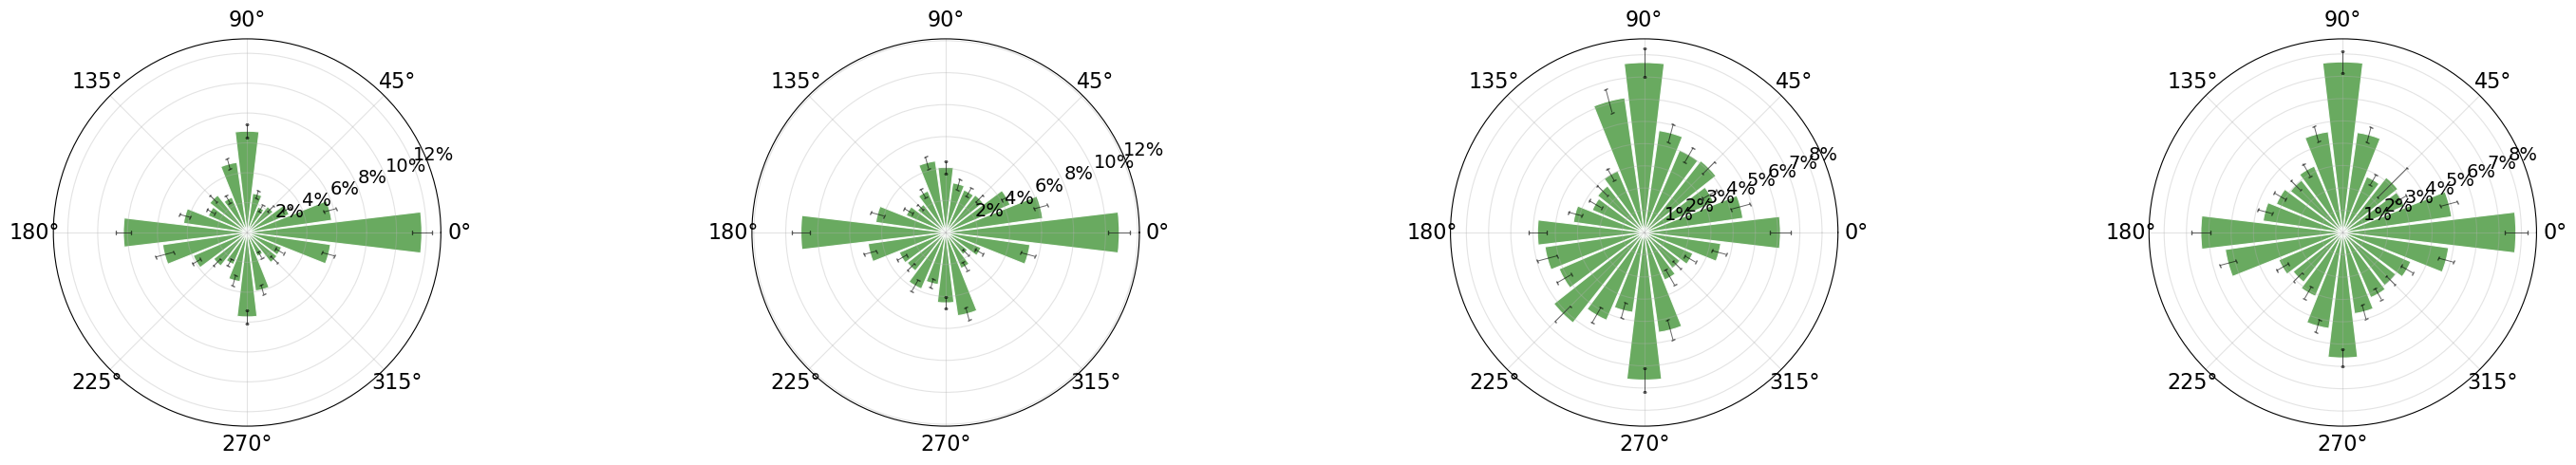

In [7]:
# =========================
# 6. Plot directional rose charts
# =========================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(30, 5),
    subplot_kw={"projection": "polar"}
)

axes = axes.flatten()

theta = np.deg2rad(
    np.arange(n_bins) * bin_width
)

colors = [
    "#59A14F",
    "#59A14F",
    "#59A14F",
    "#59A14F"
]

for ax, toi, color in zip(
    axes,
    available_tois,
    colors
):
    mean_values = group_mean.loc[toi].to_numpy()
    sem_values = group_sem.loc[toi].fillna(0).to_numpy()
    #Approximate the 95% confidence interval
    ci95 = 1.96 * sem_values

    ax.bar(
        theta,
        mean_values,
        width=np.deg2rad(bin_width * 0.9),
        color=color,
        edgecolor="white",
        linewidth=0.8,
        alpha=0.9,
        yerr=ci95,
        error_kw={
            "elinewidth": 0.7,
            "capsize": 1.5,
            "alpha": 0.6
        },

    )
    # ax.tick_params(axis='both', labelsize=15)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=14)
    # 0° points to the right
    ax.set_theta_zero_location("E")

    # Angles increase counterclockwise
    ax.set_theta_direction(1)

    ax.set_thetagrids(
        np.arange(0, 360, 45)
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=1, decimals=0)
    )

    n_participants = (
        participant_proportions
        .loc[toi]
        .shape[0]
    )

    ax.grid(alpha=0.35)

for ax in axes[len(available_tois):]:
    ax.set_visible(False)

plt.tight_layout()

plt.savefig(
    "selected_TOI_saccade_direction.png",
    dpi=300
)

plt.show()
